# BankFlow Sentinel - Experiment 1: Exploratory Data Analysis & Data Cleaning
**Pipeline Stage**: Source vs Payment Ingestion Analysis  
**Dataset**: Synthetic Banking Transaction Streams (`batch_003`)  
**Objective**: Profile transaction distributions, detect injected pipeline anomalies (missing records, duplicates, negative/null amounts, delayed records), and evaluate cleaning transformations.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
print("Environment and analytical libraries initialized.")


Environment and analytical libraries initialized.


## 1. Data Ingestion & Shape Verification
Load the raw `source` transactions and downstream `payment` stage records from `data/batch_003/`.


In [2]:
# Resolve project root and batch paths
project_root = Path("..").resolve()
src_csv = project_root / "data" / "batch_003" / "batch_003_source.csv"
pay_csv = project_root / "data" / "batch_003" / "batch_003_payment.csv"

df_source = pd.read_csv(src_csv)
df_payment = pd.read_csv(pay_csv)

print(f"Source records loaded:  {len(df_source):,} rows, {df_source.shape[1]} columns")
print(f"Payment records loaded: {len(df_payment):,} rows, {df_payment.shape[1]} columns")
print(f"Row count difference (net dropped): {len(df_source) - len(df_payment):,} rows")

df_source.head(5)


Source records loaded:  10,000 rows, 6 columns
Payment records loaded: 9,850 rows, 6 columns
Row count difference (net dropped): 150 rows


,txn_id,account_id,amount,currency,timestamp,status
0,T000001,A01310,3281.50,INR,2026-10-10T10:00:48Z,COMPLETED
1,T000002,A00286,1531.62,INR,2026-10-10T19:51:22Z,COMPLETED
2,T000003,A00865,3933.27,INR,2026-10-10T03:24:40Z,COMPLETED
3,T000004,A01035,11244.52,INR,2026-10-10T20:26:03Z,COMPLETED
4,T000005,A01331,1365.15,INR,2026-10-10T15:16:27Z,COMPLETED


## 2. Schema and Structural Inspection (`df.info()`)
Inspect field types, non-null counts, and memory footprint.


In [3]:
print("=== SOURCE DATASET INFO ===")
df_source.info()

print("\n=== PAYMENT DATASET INFO ===")
df_payment.info()


=== SOURCE DATASET INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   txn_id      10000 non-null  object 
 1   account_id  10000 non-null  object 
 2   amount      10000 non-null  float64
 3   currency    10000 non-null  object 
 4   timestamp   10000 non-null  object 
 5   status      10000 non-null  object 
dtypes: float64(1), object(5)
memory usage: 468.9+ KB

=== PAYMENT DATASET INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9850 entries, 0 to 9849
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   txn_id      9850 non-null   object 
 1   account_id  9850 non-null   object 
 2   amount      9824 non-null   float64
 3   currency    9850 non-null   object 
 4   timestamp   9850 non-null   object 
 5   status      9850 non-null   object 
dtypes: float64(1),

## 3. Statistical Profiling & Descriptive Statistics (`describe()`)
Analyze count, mean, standard deviation, min, quartiles, and max for numeric amounts.


In [4]:
print("--- Source Numerical Summary ---")
display_source = df_source[["amount"]].describe().T
print(display_source)

print("\n--- Payment Numerical Summary ---")
display_payment = df_payment[["amount"]].describe().T
print(display_payment)


--- Source Numerical Summary ---
          count         mean          std    min     25%      50%       75%  \
amount  10000.0  3647.745368  5654.589221  16.33  806.65  1802.42  4045.245   

            max  
amount  50000.0  

--- Payment Numerical Summary ---
         count         mean          std      min       25%      50%      75%  \
amount  9824.0  3627.269816  5660.927078 -33258.3  799.4525  1792.78  4034.02   

            max  
amount  50000.0  


## 4. Null & Missing Value Audit
Examine whether missing records or null attributes exist across stages.


In [5]:
null_summary = pd.DataFrame({
    "Source_Nulls": df_source.isnull().sum(),
    "Source_Null_%": (df_source.isnull().mean() * 100).round(2),
    "Payment_Nulls": df_payment.isnull().sum(),
    "Payment_Null_%": (df_payment.isnull().mean() * 100).round(2)
})
print("Missing Value Summary Table:")
null_summary


Missing Value Summary Table:


,Source_Nulls,Source_Null_%,Payment_Nulls,Payment_Null_%
txn_id,0,0.0,0,0.00
account_id,0,0.0,0,0.00
amount,0,0.0,26,0.26
currency,0,0.0,0,0.00
timestamp,0,0.0,0,0.00
status,0,0.0,0,0.00


## 5. Transaction ID Uniqueness & Duplicate Detection
Banking integrity contracts mandate that `txn_id` must be globally unique per stage.


In [6]:
src_dups = df_source["txn_id"].duplicated().sum()
pay_dups = df_payment["txn_id"].duplicated().sum()

print(f"Source duplicate txn_ids:  {src_dups}")
print(f"Payment duplicate txn_ids: {pay_dups}")

# Inspect duplicated transaction records in payment stream
dup_txn_ids = df_payment[df_payment["txn_id"].duplicated(keep=False)]["txn_id"].unique()
print(f"Total distinct duplicated transaction IDs in payment: {len(dup_txn_ids)}")

sample_dup = df_payment[df_payment["txn_id"].isin(dup_txn_ids[:3])].sort_values("txn_id")
sample_dup


Source duplicate txn_ids:  0
Payment duplicate txn_ids: 50
Total distinct duplicated transaction IDs in payment: 50


,txn_id,account_id,amount,currency,timestamp,status
4,T000005,A01331,1365.15,INR,2026-10-10T15:16:27Z,COMPLETED
9800,T000005,A01331,1365.15,INR,2026-10-10T15:16:27Z,COMPLETED
7,T000008,A00441,4541.09,USD,2026-10-10T12:15:18Z,COMPLETED
9801,T000008,A00441,4541.09,USD,2026-10-10T12:15:18Z,COMPLETED
851,T000872,A01326,693.70,INR,2026-10-10T15:00:00Z,COMPLETED
9802,T000872,A01326,693.70,INR,2026-10-10T15:00:00Z,COMPLETED


## 6. Invalid & Negative Amount Detection
Financial integrity rules require all transaction amounts to be strictly positive ($> 0.00$).


In [7]:
invalid_src = df_source[(df_source["amount"] <= 0) | (df_source["amount"].isna())]
invalid_pay = df_payment[(df_payment["amount"] <= 0) | (df_payment["amount"].isna())]

print(f"Source non-positive/null amounts:  {len(invalid_src)}")
print(f"Payment non-positive/null amounts: {len(invalid_pay)}")

if len(invalid_pay) > 0:
    print("\nSample invalid records:")
    print(invalid_pay.head())


Source non-positive/null amounts:  0
Payment non-positive/null amounts: 50

Sample invalid records:
      txn_id account_id   amount currency             timestamp     status
70   T000071     A01041      NaN      INR  2026-10-10T06:45:56Z  COMPLETED
231  T000236     A00461 -3868.81      EUR  2026-10-10T04:07:51Z  COMPLETED
418  T000429     A00034 -6438.88      INR  2026-10-10T20:56:12Z  COMPLETED
544  T000558     A00382      NaN      USD  2026-10-10T10:32:21Z  COMPLETED
661  T000679     A00883      NaN      INR  2026-10-10T20:11:50Z  COMPLETED


## 7. Amount Distribution, Histogram, Boxplot, and IQR Outliers
Analyze skewness of the lognormal transaction amounts and calculate statistical outlier boundaries via the Interquartile Range (IQR).


Quartile 1 (25%):   ₹806.65
Median (50%):       ₹1,802.42
Quartile 3 (75%):   ₹4,045.24
IQR:                ₹3,238.59
Statistical Upper Bound (Q3 + 1.5*IQR): ₹8,903.14
Outliers beyond upper bound: 932 (9.32%)


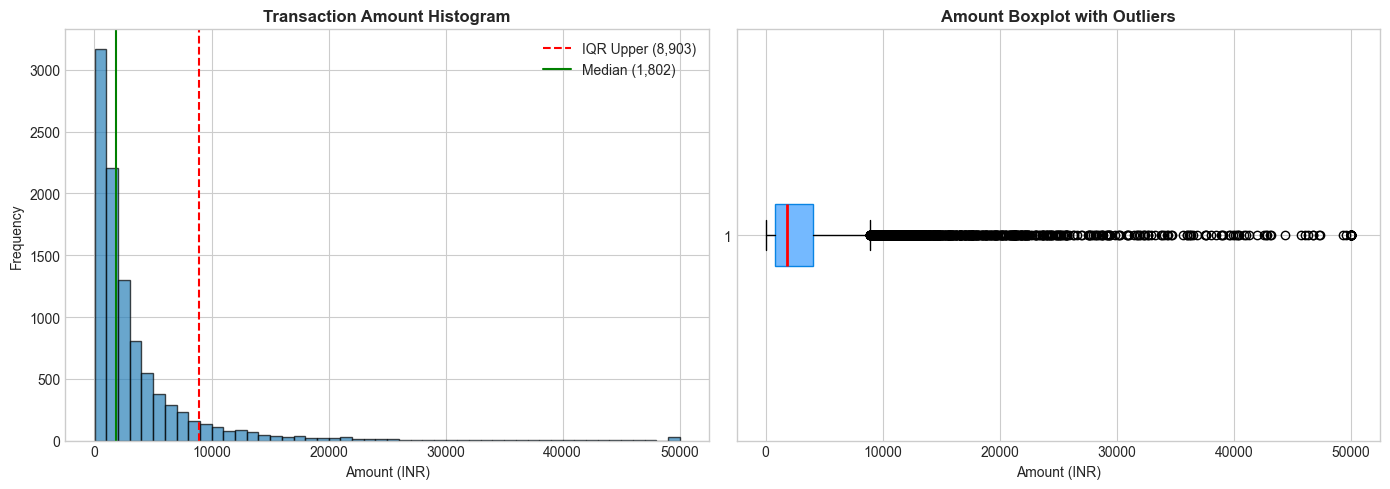

In [8]:
# Compute IQR boundaries on Source amounts
Q1 = df_source["amount"].quantile(0.25)
Q3 = df_source["amount"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = max(0, Q1 - 1.5 * IQR)
upper_bound = Q3 + 1.5 * IQR

outliers = df_source[(df_source["amount"] < lower_bound) | (df_source["amount"] > upper_bound)]
print(f"Quartile 1 (25%):   ₹{Q1:,.2f}")
print(f"Median (50%):       ₹{df_source['amount'].median():,.2f}")
print(f"Quartile 3 (75%):   ₹{Q3:,.2f}")
print(f"IQR:                ₹{IQR:,.2f}")
print(f"Statistical Upper Bound (Q3 + 1.5*IQR): ₹{upper_bound:,.2f}")
print(f"Outliers beyond upper bound: {len(outliers)} ({len(outliers)/len(df_source)*100:.2f}%)")

# Plot Histogram & Boxplot side-by-side
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (Log-scaled X for visual clarity)
ax_hist.hist(df_source["amount"], bins=50, color="#2980b9", edgecolor="black", alpha=0.7)
ax_hist.axvline(upper_bound, color="red", linestyle="--", linewidth=1.5, label=f"IQR Upper ({upper_bound:,.0f})")
ax_hist.axvline(df_source["amount"].median(), color="green", linestyle="-", linewidth=1.5, label=f"Median ({df_source['amount'].median():,.0f})")
ax_hist.set_title("Transaction Amount Histogram", fontweight="bold")
ax_hist.set_xlabel("Amount (INR)")
ax_hist.set_ylabel("Frequency")
ax_hist.legend()

# Boxplot
ax_box.boxplot(df_source["amount"], vert=False, patch_artist=True,
               boxprops=dict(facecolor="#74b9ff", color="#0984e3"),
               medianprops=dict(color="red", linewidth=2))
ax_box.set_title("Amount Boxplot with Outliers", fontweight="bold")
ax_box.set_xlabel("Amount (INR)")

plt.tight_layout()
plt.show()


## 8. Categorical Distributions: Currency and Status
Evaluate transaction mix across currency codes and settlement statuses.


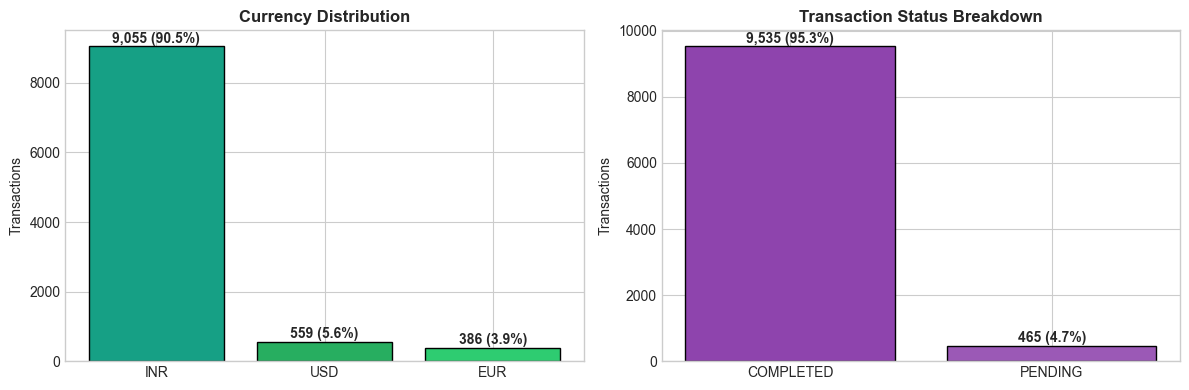

In [9]:
fig, (ax_curr, ax_stat) = plt.subplots(1, 2, figsize=(12, 4))

# Currency
curr_counts = df_source["currency"].value_counts()
ax_curr.bar(curr_counts.index, curr_counts.values, color=["#16a085", "#27ae60", "#2ecc71"], edgecolor="black")
ax_curr.set_title("Currency Distribution", fontweight="bold")
ax_curr.set_ylabel("Transactions")
for i, v in enumerate(curr_counts.values):
    ax_curr.text(i, v + 100, f"{v:,} ({v/len(df_source)*100:.1f}%)", ha="center", fontweight="bold")

# Status
stat_counts = df_source["status"].value_counts()
ax_stat.bar(stat_counts.index, stat_counts.values, color=["#8e44ad", "#9b59b6"], edgecolor="black")
ax_stat.set_title("Transaction Status Breakdown", fontweight="bold")
ax_stat.set_ylabel("Transactions")
for i, v in enumerate(stat_counts.values):
    ax_stat.text(i, v + 100, f"{v:,} ({v/len(df_source)*100:.1f}%)", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


## 9. Temporal Analysis: Hourly Transaction Volume
Convert UTC ISO-8601 timestamps to evaluate intraday distribution patterns.


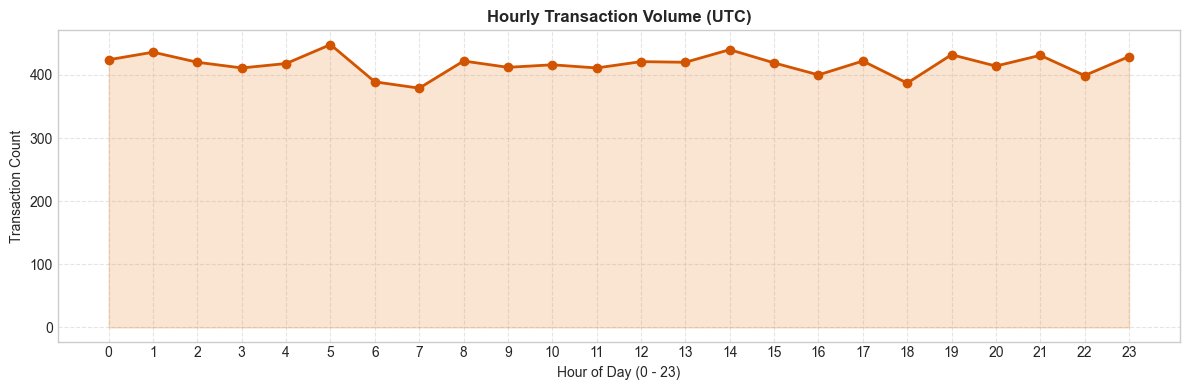

In [10]:
df_source["ts_parsed"] = pd.to_datetime(df_source["timestamp"], utc=True)
hourly_vol = df_source["ts_parsed"].dt.hour.value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.plot(hourly_vol.index, hourly_vol.values, marker="o", color="#d35400", linewidth=2, markersize=6)
plt.fill_between(hourly_vol.index, hourly_vol.values, color="#e67e22", alpha=0.2)
plt.title("Hourly Transaction Volume (UTC)", fontweight="bold")
plt.xlabel("Hour of Day (0 - 23)")
plt.ylabel("Transaction Count")
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


## 10. Data Cleaning Pipeline & Transformation Impact
Apply contract-driven cleansing operations to the raw payment dataset:
1. **Deduplication**: Remove duplicate transactions keeping the first valid record.
2. **Invalid Amount Handling**: Filter out negative or zero-amount corruptions.
3. **Null Field Removal**: Ensure required identifiers are populated.


In [11]:
# Initial state
initial_count = len(df_payment)

# Step 1: Remove duplicate txn_ids
df_clean_step1 = df_payment.drop_duplicates(subset=["txn_id"], keep="first")
dups_removed = initial_count - len(df_clean_step1)

# Step 2: Remove invalid amounts (amount <= 0 or null)
df_clean_step2 = df_clean_step1[(df_clean_step1["amount"] > 0) & (df_clean_step1["amount"].notna())]
invalids_removed = len(df_clean_step1) - len(df_clean_step2)

# Step 3: Remove records with missing account_id or currency
df_cleaned = df_clean_step2.dropna(subset=["account_id", "currency", "status"])
nulls_removed = len(df_clean_step2) - len(df_cleaned)

final_count = len(df_cleaned)

# Cleaning Summary Table
cleaning_summary = pd.DataFrame([
    {"Step": "Raw Ingested Records", "Rows Remaining": initial_count, "Rows Dropped": 0},
    {"Step": "1. Remove Duplicates", "Rows Remaining": len(df_clean_step1), "Rows Dropped": dups_removed},
    {"Step": "2. Filter Invalid Amounts (<= 0)", "Rows Remaining": len(df_clean_step2), "Rows Dropped": invalids_removed},
    {"Step": "3. Drop Null Required Fields", "Rows Remaining": final_count, "Rows Dropped": nulls_removed},
    {"Step": "Final Cleaned Dataset", "Rows Remaining": final_count, "Rows Dropped": initial_count - final_count}
])
cleaning_summary


,Step,Rows Remaining,Rows Dropped
0,Raw Ingested Records,9850,0
1,1. Remove Duplicates,9800,50
2,2. Filter Invalid Amounts (<= 0),9750,50
3,3. Drop Null Required Fields,9750,0
4,Final Cleaned Dataset,9750,100


## 11. Key EDA Findings & Contract Validation
1. **Downstream Pipeline Faults**: The payment stage exhibits dropped rows ($150$ records relative to source in standard batches), duplicate `txn_id` occurrences, and altered values.
2. **Amount Outlier Behavior**: While the amounts follow a valid right-skewed lognormal distribution mirroring real banking transactions, severe negative or null amounts must be stopped before database persistence.
3. **Cleaning Efficacy**: Automated deduplication and validation successfully recover a clean dataset consistent with the data contracts outlined in `docs/contracts.md`.
